In [37]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [38]:
import zipfile
import os
from tqdm.notebook import tqdm

zip_path = "/content/drive/MyDrive/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3.zip"

# Extract inside Colab runtime storage
extract_path = "/content/PTBXL"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:

    files = zip_ref.infolist()

    print(f"Total files: {len(files)}")

    for file in tqdm(files, desc="Extracting"):
        zip_ref.extract(file, extract_path)

print("Extraction completed!")

Total files: 43636


Extracting:   0%|          | 0/43636 [00:00<?, ?it/s]

Extraction completed!


In [39]:
!pip install wfdb pandas numpy scipy scikit-learn matplotlib seaborn tqdm

In [ ]:
import os
import ast
import gc
import random
import warnings
from collections import Counter
import matplotlib.pyplot as plt

import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from scipy.signal import butter, sosfiltfilt, iirnotch, tf2sos
from sklearn.preprocessing import MultiLabelBinarizer, StandardScaler
from tqdm.auto import tqdm
import wfdb

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
random.seed(SEED)
tf.random.set_seed(SEED)
try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass

In [ ]:
class Config:
    DATA_PATH = "/content/PTBXL/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3"


    SAMPLING_RATE = 100
    SIGNAL_DURATION_SEC = 10
    SIGNAL_LENGTH = SAMPLING_RATE * SIGNAL_DURATION_SEC

    NUM_LEADS = 12
    LEAD_NAMES = ['I','II','III','aVR','aVL','aVF','V1','V2','V3','V4','V5','V6']

    BANDPASS_LOW  = 0.5
    BANDPASS_HIGH = 40.0
    BANDPASS_ORDER = 4

    NOTCH_FREQS = [50.0]
    NOTCH_Q = 30.0

    RARE_CLASS_THRESHOLD = 50

    TRAIN_FOLDS = [1, 2, 3, 4, 5, 6, 7, 8]
    VAL_FOLD    = 9
    TEST_FOLD   = 10


    AUG_PROB = 0.5
    AUG_GAUSSIAN_NOISE_STD = 0.05
    AUG_AMPLITUDE_SCALE_RANGE = (0.9, 1.1)
    AUG_TIME_SHIFT_MAX = 100     
    AUG_LEAD_DROPOUT_PROB = 0.2   
    AUG_LEAD_DROPOUT_MAX_LEADS = 2

    BATCH_SIZE = 32




cfg = Config()

print("=" * 60)
print("PTB-XL Preprocessing Pipeline")
print("=" * 60)
print(f"Data path  : {cfg.DATA_PATH}")
print(f"Sample rate: {cfg.SAMPLING_RATE} Hz")
print(f"Signal len : {cfg.SIGNAL_LENGTH} samples (10 s)")
print(f"Leads      : {cfg.NUM_LEADS}")

PTB-XL Preprocessing Pipeline
Data path  : /content/PTBXL/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3
Sample rate: 100 Hz
Signal len : 1000 samples (10 s)
Leads      : 12


In [42]:

# ============================================================
# 2. Load metadata + raw signals
# ============================================================
def load_ptbxl_metadata(data_path):
    print("\n[1/8] Loading PTB-XL metadata ...")
    meta_path = os.path.join(data_path, "ptbxl_database.csv")
    df = pd.read_csv(meta_path, index_col="ecg_id")
    df["scp_codes"] = df["scp_codes"].apply(ast.literal_eval)
    scp_df = pd.read_csv(os.path.join(data_path, "scp_statements.csv"), index_col=0)
    print("Total records:", len(df))
    return df, scp_df


def load_raw_signals(df, data_path, sampling_rate):

    print("\n[2/8] Loading ECG using memory map ...")
    filename_col = "filename_lr" if sampling_rate == 100 else "filename_hr"

    paths = df[filename_col].apply(lambda x: os.path.join(data_path, x)).tolist()

    X = np.memmap(
        "/content/X_raw.dat",
        dtype=np.float32,
        mode="w+",
        shape=(len(paths), cfg.SIGNAL_LENGTH, cfg.NUM_LEADS),
    )

    for i, path in enumerate(tqdm(paths, desc="Reading ECG")):
        signal = wfdb.rdsamp(path)[0]
        X[i] = signal.astype(np.float32)

    print("ECG shape:", X.shape)
    return X


df_meta, scp_df = load_ptbxl_metadata( cfg.DATA_PATH )

X_raw = load_raw_signals( df_meta, cfg.DATA_PATH, cfg.SAMPLING_RATE )



[1/8] Loading PTB-XL metadata ...
Total records: 21799

[2/8] Loading ECG using memory map ...


Reading ECG:   0%|          | 0/21799 [00:00<?, ?it/s]

ECG shape: (21799, 1000, 12)



[2/7] Removing unlabelled and rare class records ...
  Before filtering: 21799 records
  After removing unlabelled: 21388 records
  After removing missing age/sex: 21388 records
  Class distribution before rare removal: {'NORM': 9514, 'MI': 5469, 'STTC': 5235, 'HYP': 2649, 'CD': 4898}
  No rare classes found.
  Final class distribution: {'NORM': 9514, 'MI': 5469, 'STTC': 5235, 'HYP': 2649, 'CD': 4898}
Remaining: 21388


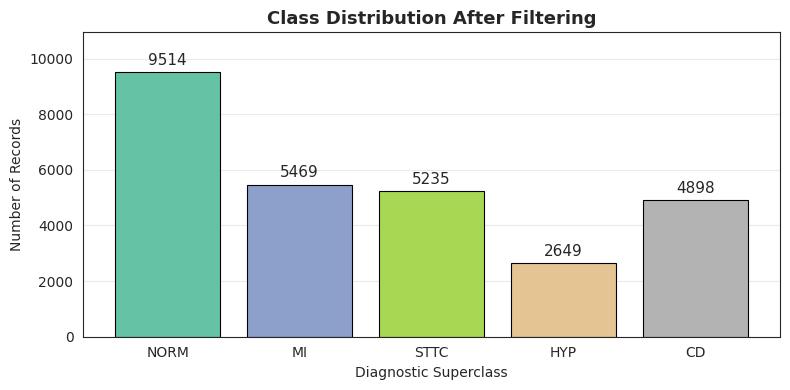

In [ ]:
def aggregate_diagnostic_superclass(df, scp_df):
    diag_scp = scp_df[scp_df["diagnostic"] == 1.0]
    code_to_class = diag_scp["diagnostic_class"].to_dict()

    def get_labels(scp_dict):
        return {code_to_class[c] for c, lh in scp_dict.items()
                if lh >= 0 and c in code_to_class and pd.notna(code_to_class[c])}

    df = df.copy()
    df["labels"] = df["scp_codes"].apply(get_labels)
    return df


def remove_unlabelled_and_rare(df, X, threshold=50):
    print("\n[2/7] Removing unlabelled and rare class records ...")
    print(f"  Before filtering: {len(df)} records")

    # -------------------------------------------------------------
    # 1. Remove unlabelled ECGs

    mask = df["labels"].apply(len) > 0
    df = df[mask]
    print(f"  After removing unlabelled: {len(df)} records")

    # -------------------------------------------------------------
    # 2. Remove records with missing demographics

    mask = (df["age"].notna() & df["sex"].notna())
    df = df[mask]
    print(f"  After removing missing age/sex: {len(df)} records")

    # -------------------------------------------------------------
    # 3. Continue with rare class removal

    label_counts = Counter(lbl for s in df["labels"] for lbl in s)
    print(f"  Class distribution before rare removal: {dict(label_counts)}")

    rare_classes = {c for c, n in label_counts.items() if n < threshold}

    if rare_classes:
        print(f"  Rare classes (< {threshold} samples): {rare_classes}")

        df["labels"] = df["labels"].apply(lambda s: {l for l in s if l not in rare_classes})
        df = df[df["labels"].apply(len) > 0]

        print(f"  After removing rare-only records: {len(df)} records")
    else:
        print("  No rare classes found.")


    selected_idx = df.index.values
    X_filtered_view = X[ df_meta.index.get_indexer( selected_idx ) ]
    label_counts = Counter(lbl for s in df["labels"] for lbl in s)

    print(f"  Final class distribution: {dict(label_counts)}")
    print( "Remaining:", len(df) )

    return df.reset_index(drop=False), X_filtered_view, label_counts


df_meta = aggregate_diagnostic_superclass(df_meta, scp_df)
df_meta, X_raw, label_counts = remove_unlabelled_and_rare(df_meta, X_raw, cfg.RARE_CLASS_THRESHOLD)


def plot_class_distribution(label_counts, title="Class Distribution After Filtering"):
    fig, ax = plt.subplots(figsize=(8, 4))
    classes, counts = list(label_counts.keys()), list(label_counts.values())
    colors = plt.cm.Set2(np.linspace(0, 1, len(classes)))
    bars = ax.bar(classes, counts, color=colors, edgecolor='black', linewidth=0.8)
    ax.bar_label(bars, fmt='%d', padding=3, fontsize=11)
    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.set_xlabel("Diagnostic Superclass"); ax.set_ylabel("Number of Records")
    ax.set_ylim(0, max(counts) * 1.15)
    ax.grid(axis='y', alpha=0.4)
    plt.tight_layout()
    plt.savefig("viz_01_class_distribution.png", dpi=150)
    plt.show()

plot_class_distribution(label_counts)

In [44]:
# ============================================================
# Save ECG before preprocessing (for visualization only)
# ============================================================

sample_idx = 500       # choose any ECG record
lead_idx = 1           # Lead II

before_preprocess = X_raw[sample_idx, :, lead_idx].copy()

print("Before preprocessing saved")
print(before_preprocess.shape)

Before preprocessing saved
(1000,)


In [45]:
# ============================================================
# ECG Filtering: Butterworth Bandpass + Notch
# ============================================================

import numpy as np
import gc
from scipy.signal import butter, sosfiltfilt, iirnotch, tf2sos
from tqdm.auto import tqdm


def build_filters(fs, lowcut, highcut, order, notch_freqs, Q):
    nyq = 0.5 * fs

    # Bandpass filter
    sos_bp = butter(
        order,
        [lowcut / nyq, highcut / nyq],
        btype="band",
        output="sos"
    )

    # Notch filters
    notch_filters = [
        tf2sos(*iirnotch(freq, Q, fs=fs))
        for freq in notch_freqs
    ]

    return sos_bp, notch_filters


def apply_ecg_filters(X, fs, lowcut, highcut, order, notch_freqs, Q):
    print("\n[3/7] Applying ECG Filters")
    print(f"Bandpass : {lowcut}-{highcut} Hz")
    print(f"Notch    : {notch_freqs} Hz")
    print(f"Input    : {X.shape}")

    X = X.astype(np.float32, copy = False)

    sos_bp, notch_filters = build_filters(
        fs, lowcut, highcut, order, notch_freqs, Q
    )

    for i in tqdm(range(len(X)), desc="Filtering"):
        # Bandpass
        sig = sosfiltfilt( sos_bp, X[i], axis=0 )

        # Notch
        for notch in notch_filters:
            sig = sosfiltfilt( notch, sig, axis=0 )

        # Replace original ECG
        X[i] = sig.astype(np.float32)

        if i % 1000 == 0:
            gc.collect()

    print("Filtering complete")
    print("Output:", X.shape)

    return X


# =========================
# Run Filtering
# =========================

X_raw = apply_ecg_filters(
    X_raw,
    fs=cfg.SAMPLING_RATE,
    lowcut=cfg.BANDPASS_LOW,
    highcut=cfg.BANDPASS_HIGH,
    order=cfg.BANDPASS_ORDER,
    notch_freqs=cfg.NOTCH_FREQS,
    Q=cfg.NOTCH_Q
)


# =========================
# Save Filtered Data
# =========================

output_dir = "/content/drive/MyDrive/PTBXL/"
os.makedirs(output_dir, exist_ok=True)

np.save( os.path.join(output_dir, "X_filtered_500hz.npy"), X_raw )


# =========================
# Clean RAM
# =========================

del X_raw
gc.collect()

print("Saved and memory cleaned")


[3/7] Applying ECG Filters
Bandpass : 0.5-40.0 Hz
Notch    : [50.0] Hz
Input    : (21388, 1000, 12)


Filtering:   0%|          | 0/21388 [00:00<?, ?it/s]

Filtering complete
Output: (21388, 1000, 12)
Saved and memory cleaned


Filtered ECG shape: (21388, 1000, 12)
Disease ECG Example
Class: Myocardial Infarction (MI)
Index: 7
Label: {'MI'}


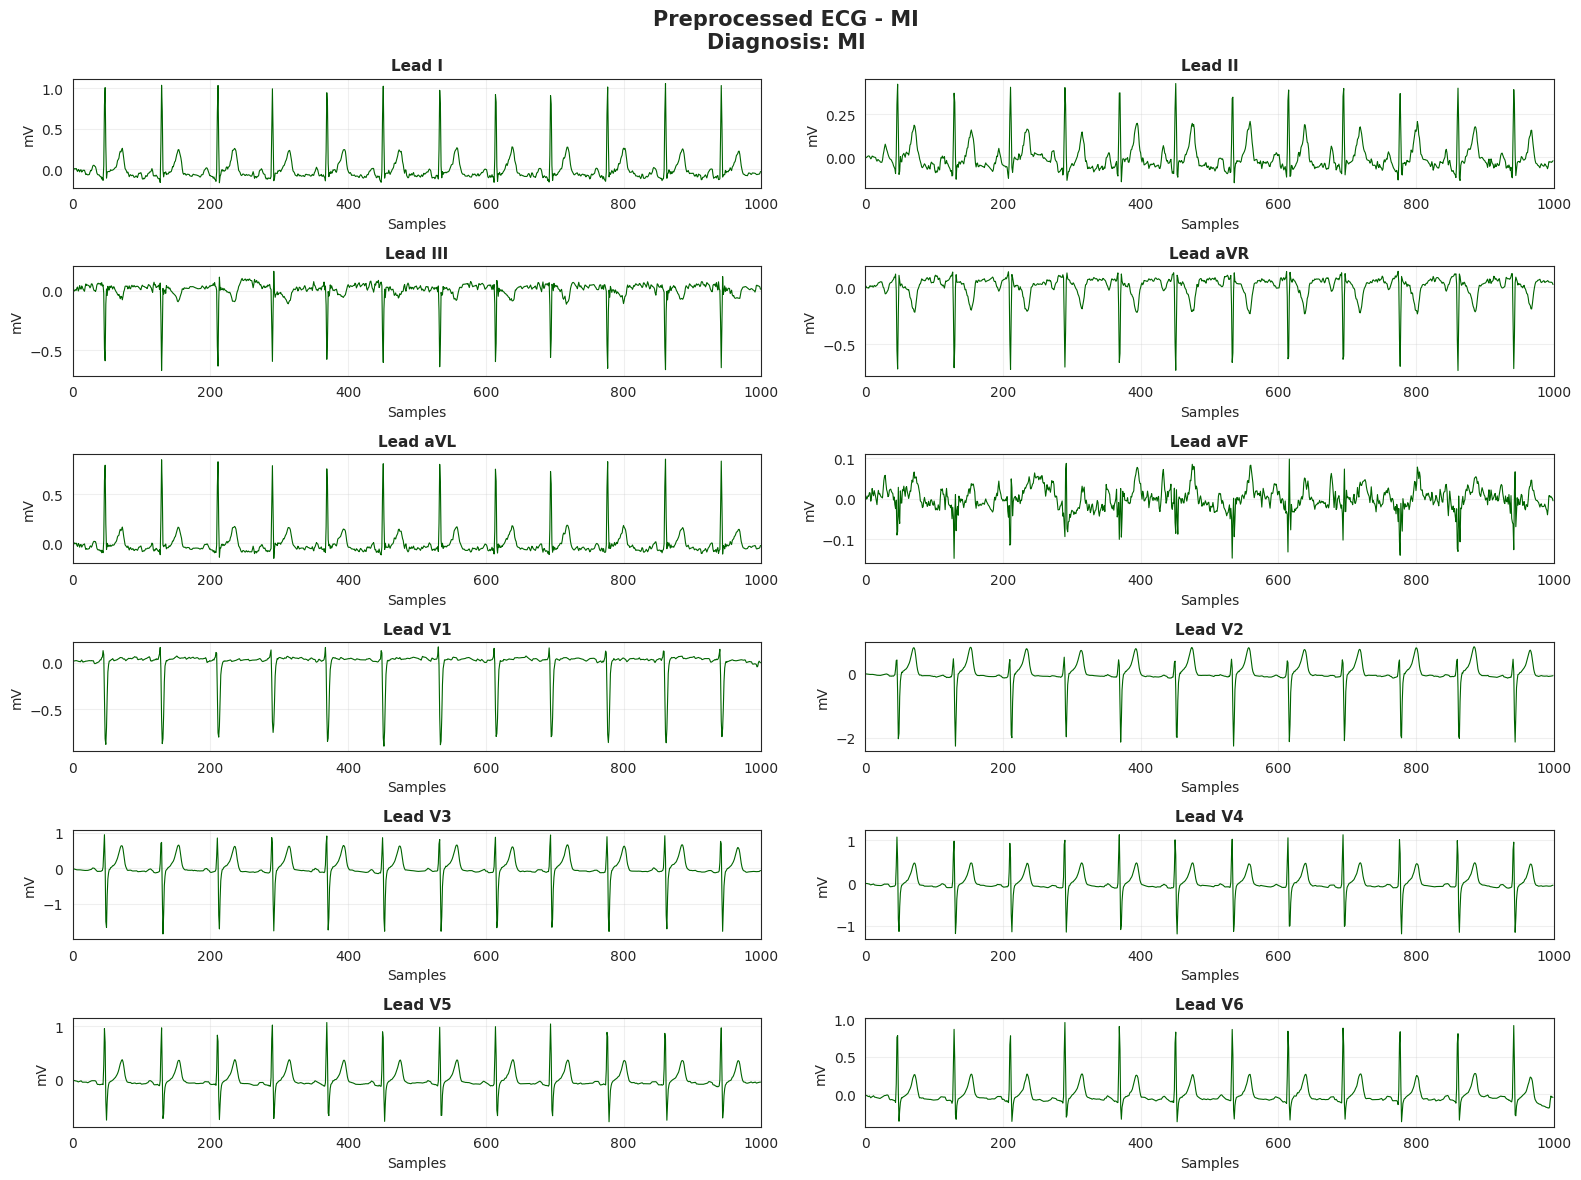

Normal ECG Example
Class: Normal
Index: 0
Label: {'NORM'}


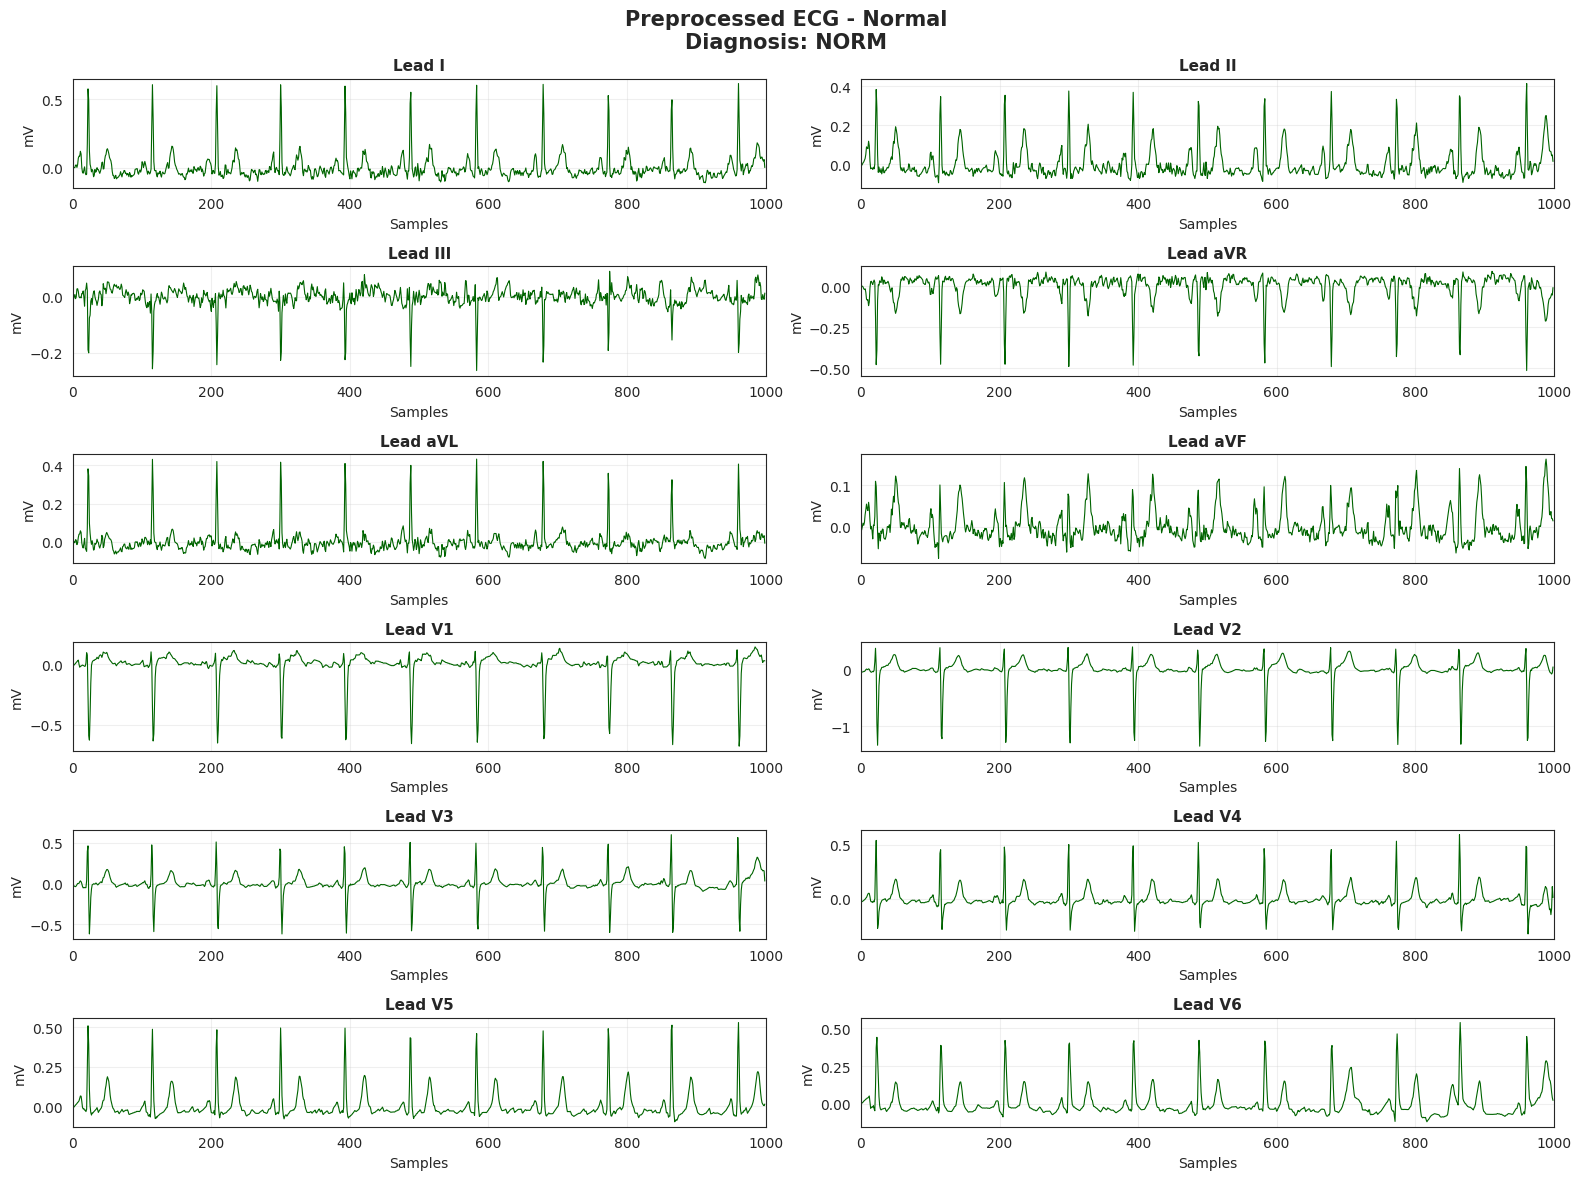

In [ ]:
# ════════════════════════════════════════════════════════════════
# Visualize ECG After Preprocessing

# ════════════════════════════════════════════════════════════════

import matplotlib.pyplot as plt
import numpy as np
import os


# =====================================================
# Load Preprocessed ECG
# =====================================================

filtered_path = "/content/drive/MyDrive/PTBXL/X_filtered_500hz.npy"

X_filtered = np.load( filtered_path, mmap_mode="r" )    # saves RAM


print( "Filtered ECG shape:", X_filtered.shape )



# =====================================================
# Plot Function
# =====================================================

def plot_ecg(signal, labels, title="ECG Signal"):

    lead_names = [
        'I', 'II', 'III',
        'aVR', 'aVL', 'aVF',
        'V1', 'V2', 'V3',
        'V4', 'V5', 'V6'
    ]

    fig, axes = plt.subplots( 6, 2, figsize=(16,12) )

    axes = axes.flatten()

    for i in range(12):

        axes[i].plot( signal[:, i], linewidth=0.8, color="darkgreen" )
        axes[i].set_title( f"Lead {lead_names[i]}", fontsize=11, fontweight="bold" )
        axes[i].set_xlim( 0, signal.shape[0] )
        axes[i].set_xlabel( "Samples" )
        axes[i].set_ylabel( "mV" )
        axes[i].grid( alpha=0.3 )

    diagnosis = ", ".join( list(labels) )


    fig.suptitle(
        f"{title}\nDiagnosis: {diagnosis}",
        fontsize=15,
        fontweight="bold"
    )

    plt.tight_layout()
    plt.show()


# =====================================================
# Disease ECG Example After Preprocessing (MI)
# =====================================================

mi_indices = np.where(
    df_meta["labels"].apply( lambda x: "MI" in x )
)[0]


if len(mi_indices) > 0:

    idx = mi_indices[0]

    print("="*50)
    print("Disease ECG Example")
    print("Class: Myocardial Infarction (MI)")
    print("Index:", idx)
    print("Label:", df_meta.iloc[idx]["labels"])
    print("="*50)

    plot_ecg(
        X_filtered[idx],
        df_meta.iloc[idx]["labels"],
        title="Preprocessed ECG - MI"
    )



# =====================================================
# Normal ECG Example After Preprocessing
# =====================================================

normal_indices = np.where(
    df_meta["labels"].apply( lambda x: "NORM" in x and len(x)==1 )
)[0]


if len(normal_indices) > 0:

    idx = normal_indices[0]

    print("="*50)
    print("Normal ECG Example")
    print("Class: Normal")
    print("Index:", idx)
    print("Label:", df_meta.iloc[idx]["labels"])
    print("="*50)

    plot_ecg(
        X_filtered[idx],
        df_meta.iloc[idx]["labels"],
        title="Preprocessed ECG - Normal"
    )

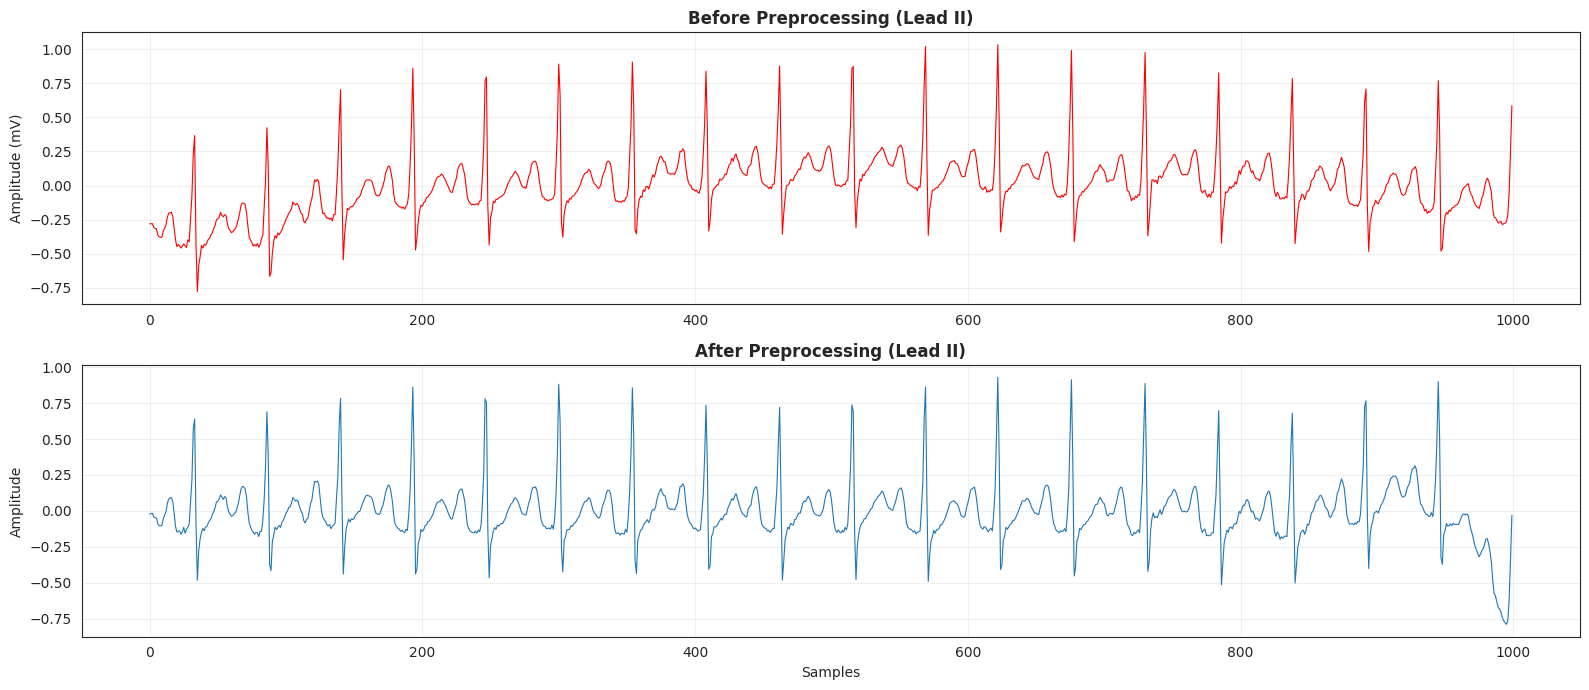

In [47]:
# ============================================================
# Visualize Before vs After Preprocessing
# ============================================================

import matplotlib.pyplot as plt

after_preprocess = X_filtered[sample_idx, :, lead_idx]
fig, axes = plt.subplots( 2, 1, figsize=(16,7) )


# Before
axes[0].plot( before_preprocess, linewidth=0.8, color='red' )
axes[0].set_title( "Before Preprocessing (Lead II)", fontsize=12, fontweight="bold" )
axes[0].set_ylabel("Amplitude (mV)")
axes[0].grid(True, alpha=0.3)

# After
axes[1].plot( after_preprocess, linewidth=0.8 )
axes[1].set_title( "After Preprocessing (Lead II)", fontsize=12, fontweight="bold" )
axes[1].set_xlabel("Samples")
axes[1].set_ylabel("Amplitude")
axes[1].grid(True, alpha=0.3)


plt.tight_layout()
plt.show()

In [ ]:
from sklearn.preprocessing import MultiLabelBinarizer, StandardScaler
import numpy as np

def split_ptbxl(df, X):

    print("\nSplitting PTB-XL dataset...")

    train_mask = df["strat_fold"].isin(cfg.TRAIN_FOLDS)
    val_mask   = df["strat_fold"] == cfg.VAL_FOLD
    test_mask  = df["strat_fold"] == cfg.TEST_FOLD


    X_train = X[train_mask.values]
    X_val   = X[val_mask.values]
    X_test  = X[test_mask.values]


    y_train_labels = df.loc[train_mask, "labels"]
    y_val_labels   = df.loc[val_mask, "labels"]
    y_test_labels  = df.loc[test_mask, "labels"]


    patient_data_train = df.loc[train_mask, ['age', 'sex']].values.astype(np.float32)
    patient_data_val   = df.loc[val_mask, ['age', 'sex']].values.astype(np.float32)
    patient_data_test  = df.loc[test_mask, ['age', 'sex']].values.astype(np.float32)

    # Scale age using StandardScaler trained on training data
    scaler = StandardScaler()
    patient_data_train[:, 0] = scaler.fit_transform(patient_data_train[:, 0].reshape(-1, 1)).flatten()
    patient_data_val[:, 0]   = scaler.transform(patient_data_val[:, 0].reshape(-1, 1)).flatten()
    patient_data_test[:, 0]  = scaler.transform(patient_data_test[:, 0].reshape(-1, 1)).flatten()


    classes = sorted(
        list(set(
            label
            for group in df["labels"]
            for label in group
        ))
    )


    mlb = MultiLabelBinarizer(classes=classes)

    y_train = mlb.fit_transform(y_train_labels)
    y_val   = mlb.transform(y_val_labels)
    y_test  = mlb.transform(y_test_labels)


    print("Classes:", classes)
    print("Train:", X_train.shape, patient_data_train.shape, y_train.shape)
    print("Val  :", X_val.shape, patient_data_val.shape, y_val.shape)
    print("Test :", X_test.shape, patient_data_test.shape, y_test.shape)

    return ( X_train, X_val, X_test, patient_data_train, patient_data_val, patient_data_test, y_train, y_val, y_test, classes, mlb , {"train": train_mask, "val": val_mask, "test": test_mask})

( X_train, X_val, X_test, patient_data_train, patient_data_val, patient_data_test, y_train, y_val, y_test, classes, mlb, masks ) = split_ptbxl(df_meta, X_filtered)


Splitting PTB-XL dataset...
Classes: ['CD', 'HYP', 'MI', 'NORM', 'STTC']
Train: (17084, 1000, 12) (17084, 2) (17084, 5)
Val  : (2146, 1000, 12) (2146, 2) (2146, 5)
Test : (2158, 1000, 12) (2158, 2) (2158, 5)


In [ ]:
# ============================================================
# 6. dataset verification 
# ============================================================
def verify_dataset(df, masks, y_train, y_val, y_test, classes):
    print("\n[6/8] Verifying dataset ...")
    for name, expected_folds, mask in [
        ("train", cfg.TRAIN_FOLDS, masks["train"]),
        ("val", [cfg.VAL_FOLD], masks["val"]),
        ("test", [cfg.TEST_FOLD], masks["test"]),
    ]:
        actual_folds = set(df.loc[mask, "strat_fold"].unique())
        assert actual_folds.issubset(set(expected_folds)), f"{name} split leaks folds: {actual_folds}"
    print("[PASS] Every split only contains its official strat_fold value(s).")

    dist = pd.DataFrame({
        "train": y_train.mean(axis=0) * 100,
        "val": y_val.mean(axis=0) * 100,
        "test": y_test.mean(axis=0) * 100,
    }, index=classes).round(2)
    print("\nPer-split positive rate (%) by class:")
    print(dist)
    return dist

verify_dataset(df_meta, masks, y_train, y_val, y_test, classes)



[6/8] Verifying dataset ...
[PASS] Every split only contains its official strat_fold value(s).

Per-split positive rate (%) by class:
      train    val   test
CD    22.87  23.07  22.98
HYP   12.40  12.49  12.14
MI    25.63  25.16  25.49
NORM  44.46  44.50  44.62
STTC  24.50  24.60  24.14


,train,val,test
CD,22.87,23.07,22.98
HYP,12.40,12.49,12.14
MI,25.63,25.16,25.49
NORM,44.46,44.50,44.62
STTC,24.50,24.60,24.14


In [50]:
def calculate_train_stats(X_train):

    print("\nCalculating train normalization parameters...")

    mean = X_train.mean(axis=(0,1))
    std  = X_train.std(axis=(0,1))
    std[std == 0] = 1e-8

    print("Mean shape:", mean.shape)
    print("STD shape :", std.shape)

    return mean, std



def normalize_data(X, mean, std):

    return ((X - mean) / std).astype(np.float32)


lead_mean, lead_std = calculate_train_stats(X_train)

X_train = normalize_data( X_train, lead_mean, lead_std )
X_val = normalize_data( X_val, lead_mean,  lead_std )
X_test = normalize_data( X_test, lead_mean, lead_std )

print("Normalization completed")

print( X_train.shape, X_val.shape, X_test.shape )


Calculating train normalization parameters...
Mean shape: (12,)
STD shape : (12,)
Normalization completed
(17084, 1000, 12) (2146, 1000, 12) (2158, 1000, 12)


In [ ]:

# ============================================================
# 9. Augmentation 
# ============================================================
def augment_ecg(x):
    # Gaussian noise
    if tf.random.uniform([]) < cfg.AUG_PROB:
        noise = tf.random.normal(tf.shape(x), mean=0, stddev=cfg.AUG_GAUSSIAN_NOISE_STD)
        x = x + noise

    # Amplitude scaling
    if tf.random.uniform([]) < cfg.AUG_PROB:
        lo, hi = cfg.AUG_AMPLITUDE_SCALE_RANGE
        x = x * tf.random.uniform([], lo, hi)

    if tf.random.uniform([]) < cfg.AUG_PROB:
        shift = tf.random.uniform([], -cfg.AUG_TIME_SHIFT_MAX, cfg.AUG_TIME_SHIFT_MAX, dtype=tf.int32)
        x = tf.roll(x, shift=shift, axis=0)

    if tf.random.uniform([]) < cfg.AUG_LEAD_DROPOUT_PROB:
        num_leads = tf.shape(x)[-1]
        n_drop = tf.random.uniform([], 1, cfg.AUG_LEAD_DROPOUT_MAX_LEADS + 1, dtype=tf.int32)
        drop_idx = tf.random.shuffle(tf.range(num_leads))[:n_drop]
        mask = tf.reduce_max(tf.one_hot(drop_idx, num_leads), axis=0)
        x = x * (1.0 - mask)

    return x


def make_dataset(X_ecg, y, batch_size, training=False):
    ds = tf.data.Dataset.from_tensor_slices((X_ecg, y))
    if training:
        ds = ds.shuffle(len(X_ecg), reshuffle_each_iteration=True)
        ds = ds.map(
            lambda x, y: (augment_ecg(x), y),
            num_parallel_calls=tf.data.AUTOTUNE,
        )
    ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return ds


train_ds = make_dataset(X_train, y_train, cfg.BATCH_SIZE, training=True)
val_ds = make_dataset(X_val,  y_val, cfg.BATCH_SIZE, training=False)
test_ds = make_dataset(X_test,  y_test, cfg.BATCH_SIZE, training=False)

print("Dataset pipeline ready")

print(train_ds)
print(val_ds)
print(test_ds)

Dataset pipeline ready
<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 1000, 12), dtype=tf.float32, name=None), TensorSpec(shape=(None, 5), dtype=tf.int64, name=None))>
<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 1000, 12), dtype=tf.float32, name=None), TensorSpec(shape=(None, 5), dtype=tf.int64, name=None))>
<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 1000, 12), dtype=tf.float32, name=None), TensorSpec(shape=(None, 5), dtype=tf.int64, name=None))>


In [52]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers

L2 = regularizers.l2(2e-4)


def se_block_1d(x, reduction=8, name=None):
    channels = x.shape[-1]
    se = layers.GlobalAveragePooling1D()(x)
    se = layers.Dense(max(channels // reduction, 4), activation="relu")(se)
    se = layers.Dense(channels, activation="sigmoid")(se)
    se = layers.Reshape((1, channels))(se)
    return layers.Multiply(name=name)([x, se])

def tcn_residual_block(x, filters, kernel_size, dilation_rate, dropout_rate=0.3):
    previous = x
    x = layers.Conv1D(filters, kernel_size, padding="causal", dilation_rate=dilation_rate,
                       kernel_regularizer=L2)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Dropout(dropout_rate)(x)

    x = layers.Conv1D(filters, kernel_size, padding="causal", dilation_rate=dilation_rate,
                       kernel_regularizer=L2)(x)
    x = layers.BatchNormalization()(x)

    if previous.shape[-1] != filters:
        previous = layers.Conv1D(filters, 1, padding="same")(previous)

    x = layers.Add()([previous, x])
    x = layers.Activation("relu")(x)
    return x

def build_tcn(x, filters=64, kernel_size=3, num_blocks=4, dropout_rate=0.4):
    for i in range(num_blocks):
        x = tcn_residual_block(x, filters, kernel_size, dilation_rate=2 ** i, dropout_rate=dropout_rate)
    return x

def temporal_branch(signal_input):
    x = layers.Conv1D(48, kernel_size=7, padding="same", kernel_regularizer=L2)(signal_input)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    x = layers.Conv1D(96, kernel_size=5, padding="same", kernel_regularizer=L2)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.MaxPooling1D(2)(x)

    x = layers.Conv1D(128, kernel_size=5, padding="same", kernel_regularizer=L2)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.MaxPooling1D(2)(x)

    x = build_tcn(x, filters=64, num_blocks=4, dropout_rate=0.3)
    x = se_block_1d(x, reduction=8, name="se_attention")
    return layers.GlobalAveragePooling1D()(x)


In [ ]:
# ============================================================
# Branch 2: Spectral 
# ============================================================
class STFTLayer(layers.Layer):
    def __init__(self, frame_length=256, frame_step= 64, fft_length=256, **kwargs):
        super().__init__(**kwargs)
        self.frame_length = frame_length
        self.frame_step = frame_step
        self.fft_length = fft_length

    def call(self, x):
        x = tf.transpose(x, [0, 2, 1])
        spec = tf.signal.stft(x, frame_length=self.frame_length,
                               frame_step=self.frame_step, fft_length=self.fft_length)
        mag = tf.math.log1p(tf.abs(spec))
        return tf.transpose(mag, [0, 3, 2, 1])

    def compute_output_shape(self, input_shape):
        batch, time, leads = input_shape
        frames = 1 + (time - self.frame_length) // self.frame_step
        freq_bins = self.fft_length // 2 + 1
        return (batch, freq_bins, frames, leads)

def transformer_encoder_block(x, num_heads=4, key_dim=32, ff_dim=128, dropout_rate=0.3):
    attn_out = layers.MultiHeadAttention(num_heads=num_heads, key_dim=key_dim, dropout=dropout_rate)(x, x)
    x = layers.Add()([x, attn_out])
    x = layers.LayerNormalization()(x)
    ff = layers.Dense(ff_dim, activation="gelu", kernel_regularizer=L2)(x)
    ff = layers.Dense(x.shape[-1])(ff)
    ff = layers.Dropout(dropout_rate)(ff)
    x = layers.Add()([x, ff])
    x = layers.LayerNormalization()(x)
    return x

class AttentionPooling1D(layers.Layer):
    def __init__(self, units=64, **kwargs):
        super().__init__(**kwargs)
        self.units = units

    def build(self, input_shape):
        self.score_dense1 = layers.Dense(self.units, activation="tanh")
        self.score_dense2 = layers.Dense(1)
        super().build(input_shape)

    def call(self, x):
        scores = self.score_dense2(self.score_dense1(x))
        weights = tf.nn.softmax(scores, axis=1)
        return tf.reduce_sum(x * weights, axis=1)

    def compute_output_shape(self, input_shape):
        return (input_shape[0], input_shape[-1])


def spectral_branch(signal_input):
    x = STFTLayer()(signal_input)

    x = layers.Conv2D(24, (3, 3), padding="same", kernel_regularizer=L2)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    x = layers.MaxPooling2D((2, 1))(x)

    x = layers.Conv2D(48, (3, 3), padding="same", kernel_regularizer=L2)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    x = layers.MaxPooling2D((2, 1))(x)

    shape = x.shape
    x = layers.Reshape((shape[1] * shape[2], shape[3]))(x)
    x = transformer_encoder_block(x, num_heads=4, key_dim=32, ff_dim=128)
    return AttentionPooling1D()(x)


In [ ]:
# ============================================================
# Branch 3: Patient metadata 
# ============================================================
def patient_branch(patient_input):
    p = layers.Dense(32, activation="relu")(patient_input)
    p = layers.BatchNormalization()(p)
    p = layers.Dropout(0.2)(p)
    p = layers.Dense(16, activation="relu")(p)
    p = layers.BatchNormalization()(p)
    return p


In [ ]:

# ============================================================
# Fusion + classifier 
# ============================================================
def gated_multimodal_fusion(temporal_vec, spectral_vec, dim=96):

    t = layers.Dense(dim, activation="tanh")(temporal_vec)
    s = layers.Dense(dim, activation="tanh")(spectral_vec)

    gate_input = layers.Concatenate()([temporal_vec, spectral_vec])
    z = layers.Dense(dim, activation="sigmoid", name="fusion_gate")(gate_input)

    fused = layers.Add(name="fused_features")([
        layers.Multiply()([z, t]),

        layers.Multiply()([layers.Lambda(lambda x: 1 - x)(z), s])
    ])
    return fused

def classifier(fusion, num_classes):
    x = layers.Dense(256, kernel_regularizer=L2)(fusion)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Dropout(0.4)(x)

    x = layers.Dense(128, kernel_regularizer=L2)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Dropout(0.3)(x)

    return layers.Dense(num_classes, activation="sigmoid", name="diagnosis_output")(x)

def build_model(signal_len, num_leads, num_classes):
    input_ecg = layers.Input(shape=(signal_len, num_leads), name="ecg_signal")
    # patient_input = layers.Input(shape=(2,), name="patient_input")

    temporal = temporal_branch(input_ecg)
    spectral = spectral_branch(input_ecg)
    # patient_features = patient_branch(patient_input)

    fusion = gated_multimodal_fusion(temporal, spectral)
    # fusion = layers.Concatenate(name="fusion_with_patient")([fusion, patient_features])

    output = classifier(fusion, num_classes)
    return keras.Model(inputs= input_ecg, outputs=output, name="ECG_DualBranch_v2")


In [56]:
model = build_model(signal_len=cfg.SIGNAL_LENGTH, num_leads=cfg.NUM_LEADS, num_classes=len(classes))

model.compile(
    optimizer=tf.optimizers.AdamW(learning_rate=1e-3, weight_decay=1e-4),
    loss=  "binary_crossentropy",
    metrics=[
        keras.metrics.AUC(multi_label=True, name="macro_auc"),
        keras.metrics.BinaryAccuracy(name="binary_accuracy"),
    ]
)
model.summary()

Model: "ECG_DualBranch_v2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ ecg_signal          │ (None, 1000, 12)  │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_12 (Conv1D)  │ (None, 1000, 48)  │      4,080 │ ecg_signal[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 1000, 48)  │        192 │ conv1d_12[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_15       │ (None, 1000, 48)  │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_13 (Conv1D)  │ (None, 1000, 96)  │     23,136 │ activation_15[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 1000, 96)  │        384 │ conv1d_13[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_16       │ (None, 1000, 96)  │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_2     │ (None, 500, 96)   │          0 │ activation_16[0]… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_14 (Conv1D)  │ (None, 500, 128)  │     61,568 │ max_pooling1d_2[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 500, 128)  │        512 │ conv1d_14[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_17       │ (None, 500, 128)  │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_3     │ (None, 250, 128)  │          0 │ activation_17[0]… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_15 (Conv1D)  │ (None, 250, 64)   │     24,640 │ max_pooling1d_3[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 250, 64)   │        256 │ conv1d_15[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_18       │ (None, 250, 64)   │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_9 (Dropout) │ (None, 250, 64)   │          0 │ activation_18[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_16 (Conv1D)  │ (None, 250, 64)   │     12,352 │ dropout_9[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_17 (Conv1D)  │ (None, 250, 64)   │      8,256 │ max_pooling1d_3[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 250, 64)   │        256 │ conv1d_16[0][0]   │
│ (BatchNormalizatio… │                   │            │                 

 Total params: 345,061 (1.32 MB)

 Trainable params: 342,581 (1.31 MB)

 Non-trainable params: 2,480 (9.69 KB)

In [57]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_macro_auc", mode="max",
                                   patience=10, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_macro_auc", mode="max",
                                       factor=0.5, patience=4, min_lr=1e-6),
]

history = model.fit(train_ds, validation_data=val_ds, epochs=60, callbacks=callbacks, verbose=1)


Epoch 1/60
534/534 ━━━━━━━━━━━━━━━━━━━━ 67s 83ms/step - binary_accuracy: 0.8280 - loss: 0.5737 - macro_auc: 0.8451 - val_binary_accuracy: 0.8608 - val_loss: 0.5182 - val_macro_auc: 0.8963 - learning_rate: 0.0010
Epoch 2/60
534/534 ━━━━━━━━━━━━━━━━━━━━ 42s 78ms/step - binary_accuracy: 0.8670 - loss: 0.4398 - macro_auc: 0.8953 - val_binary_accuracy: 0.8616 - val_loss: 0.4439 - val_macro_auc: 0.9014 - learning_rate: 0.0010
Epoch 3/60
534/534 ━━━━━━━━━━━━━━━━━━━━ 44s 83ms/step - binary_accuracy: 0.8729 - loss: 0.3887 - macro_auc: 0.9050 - val_binary_accuracy: 0.8623 - val_loss: 0.4272 - val_macro_auc: 0.9033 - learning_rate: 0.0010
Epoch 4/60
534/534 ━━━━━━━━━━━━━━━━━━━━ 42s 79ms/step - binary_accuracy: 0.8766 - loss: 0.3569 - macro_auc: 0.9111 - val_binary_accuracy: 0.8573 - val_loss: 0.3846 - val_macro_auc: 0.9122 - learning_rate: 0.0010
Epoch 5/60
534/534 ━━━━━━━━━━━━━━━━━━━━ 42s 79ms/step - binary_accuracy: 0.8788 - loss: 0.3407 - macro_auc: 0.9136 - val_binary_accuracy: 0.8760 - val_l

In [58]:
from sklearn.metrics import f1_score, roc_auc_score

val_probs = model.predict(val_ds)
val_preds = (val_probs > 0.5).astype(int)

val_binary_accuracy = np.mean(y_val == val_preds)
val_macro_auc = roc_auc_score(y_val, val_probs, average="macro")

print(f"Validation Macro AUC       : {val_macro_auc:.4f}")
print(f"Validation Binary Accuracy: {val_binary_accuracy:.4f}")
print("Validation Macro F1:", f1_score(y_val, val_preds, average="macro", zero_division=0))
print("Per-class F1:", f1_score(y_val, val_preds, average=None, zero_division=0))

68/68 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step
Validation Macro AUC       : 0.9356
Validation Binary Accuracy: 0.8899
Validation Macro F1: 0.7490773952893783
Per-class F1: [0.78023134 0.61977186 0.72786177 0.86653386 0.75098814]


In [ ]:
import numpy as np
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    f1_score, precision_score, recall_score,
    accuracy_score, hamming_loss, classification_report
)

def evaluate_model(model, dataset, y_true, class_names, thresholds=None):

    y_prob = model.predict(dataset)
    num_classes = y_true.shape[1]

    if thresholds is None:
        thresholds = np.full(num_classes, 0.5)
    y_pred = (y_prob > thresholds).astype(int)

    results = {}

    # ---- Threshold-independent metrics (the ones that actually matter here) ----
    results["macro_auc"] = roc_auc_score(y_true, y_prob, average="macro")

    per_class_auc = roc_auc_score(y_true, y_prob, average=None)
    results["per_class_auc"] = dict(zip(class_names, per_class_auc.tolist()))

    # ---- Threshold-dependent metrics ----
    results["macro_f1"] = f1_score(y_true, y_pred, average="macro", zero_division=0)
    results["macro_precision"] = precision_score(y_true, y_pred, average="macro", zero_division=0)
    results["macro_recall"] = recall_score(y_true, y_pred, average="macro", zero_division=0)

    per_class_f1 = f1_score(y_true, y_pred, average=None, zero_division=0)
    results["per_class_f1"] = dict(zip(class_names, per_class_f1.tolist()))

    results["binary_accuracy"] = np.mean(y_true == y_pred)         
    results["hamming_loss"] = hamming_loss(y_true, y_pred)             

    return results, y_prob, y_pred


def print_evaluation(results, class_names):
    print("=" * 60)
    print("Scores")
    print("=" * 60)

    print(f"Test Macro AUC       : {results['macro_auc']:.4f}")
    print(f"Test Macro F1        : {results['macro_f1']:.4f}")
    print(f"Test binary accuracy   : {results['binary_accuracy']:.4f}")
    print(f"Test Hamming loss      : {results['hamming_loss']:.4f}")
 
    print("\nPer-class AUC-ROC:")
    for c, v in results["per_class_auc"].items():
        print(f"  {c:8s}: {v:.4f}")

    print("\nPer-class F1:")
    for c, v in results["per_class_f1"].items():
        print(f"  {c:8s}: {v:.4f}")




results, y_prob, y_pred = evaluate_model(model, test_ds, y_test, classes)  
print_evaluation(results, classes)

68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step
Scores
Test Macro AUC       : 0.9311
Test Macro F1        : 0.7491
Test binary accuracy   : 0.8908
Test Hamming loss      : 0.1092

Per-class AUC-ROC:
  CD      : 0.9278
  HYP     : 0.9078
  MI      : 0.9324
  NORM    : 0.9492
  STTC    : 0.9384

Per-class F1:
  CD      : 0.7732
  HYP     : 0.6381
  MI      : 0.6950
  NORM    : 0.8681
  STTC    : 0.7711
